## to do:

QoL
- plot nodes at any level of transform, see all_nodes
- automatically perform max. level transform
- plot single node by path
- time [s] instead of coefficient number
- automatically perform nodes2data on inverse
- fix plots

studentship:
- sensitivity analysis
- testing/tuning thresholding values (classification without machine learning)
- check out tree diagram
- sounds like a report. manuscript should be concise.
- explain the problem you're trying to address in the intro. as well as physics (materials and methods.)
- trying to find a quantitative relationship between cavitation and physical effects.
- write about alternative methods to analyse pcd data
- create filter diagram for wpt in intro, explaining the naming conventions for the levels, node number, coefficient number, etc.
- add entropy and other features that we will use. 
- write up feature selection
- use the silhouette score to test k-means with different numbers of clusters with different types of signals.
- find fundamental papers that I used for feature selection and clustering. (send them)
- generate dynamics data

algorithm
- stick with minimum entropy, find good filter (db order). implement algorithm that does this.
- test with different number of cycles.
- test normalised energy
- use tree graph to make filter bank diagram.

general coding:
- adaptive algorithm

writing:
- write about k-means
- add stuff to the literature review about the other works.

numerical results section:
- stable, stable with weak transients, fully transient (doesn't occur in practice)
- add noise to each
- might be able to do something with the database

# Decompose a signal to its components at different frequency bands with WPT

In this notebook we aim to test WPT for extracting different components of a signal based on the energy, kurtosis, and crest factor of different frequency bands. The WPT library requires python3.6+ version. The following cell checks this requirement.

In [2]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

Import the wavelet_transform package and required libraries.

In [3]:
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats

# matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np
import pywt
import scipy.stats as sc

Specify the parameters for generating a synthetic signal and to perform wavelet packet transform.

In [4]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [1, 0.8, 0.4]  # amplitude of each sine wave
frequencies = [5, 15, 25]  # frequency content of signal
phases = [0, np.deg2rad(45), np.deg2rad(120)]  # phase of each sine wave

duration = 1000 / min(frequencies)  # duration of wave

trans_amp = [10 for _ in range(5)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db20"
levels = 5
mode = "symmetric"

sort_by = 'energy'  # 'energy', 'kurtosis', 'crest', 'False' -> freq
sort = "rec"  # 'rec' (reconstructed signal) 'coef' (transform coefficients)
n_highest = 3

fft_lim = 50  # increase value to view more of the fft plots

Generate synthetic multitonal signal with/without additive noise. We will fft the signal to double check the frequency contents.

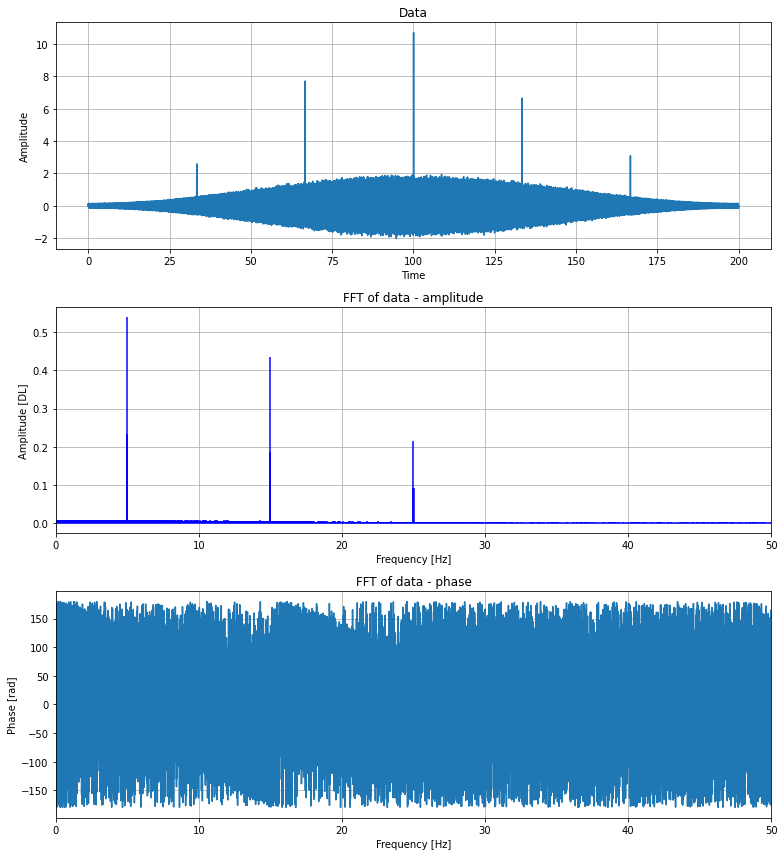

In [5]:
# generate sound wave
data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
data += sd.transients(trans_amp, trans_time, trans_dur, duration, sampling_rate)
data += sd.noise(std_noise,duration,sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

### Frequency content of reconstructed subbands
Decompose signal using discrete wavelet packet transform and sort the nodes in order of energy, kurtosis, or crest factor.

functions used for sorting

In [6]:
def sort_nodes(rec, sort="rec", sort_by="energy"):
    """
    choose how to sort the subbands

    Parameters
    ----------
    rec: tuple
        tuple containing (coefficients,reconstructed_wave,fft_of_rec_wave,energy,kurtosis,crest)
    sort: str
        sort by 'energy', 'kurtosis', or 'crest' factor
    coef_or_rec: str
        sort by calculating attributes of the node coefficients or the reconstructed wave

    returns
    -------
    rec: tuple
        sorted input
    """
    if sort == "rec":
        if sort_by == "energy": 
            return sorted(rec, key=lambda x: x[3], reverse=True)
        elif sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[4], reverse=True)
        elif sort_by == "crest":
            return sorted(rec, key=lambda x: x[4], reverse=True)
            


    elif sort == "coef":
        if sort_by == "energy":
            return sorted(rec, key=lambda x: x[0].energy, reverse=True)
        if sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[0].kurtosis, reverse=True)
        if sort_by == "crest":
            return sorted(rec, key=lambda x: x[0].crest_factor, reverse=True)

Transform and sort nodes

In [7]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
rec = []

for node in tr_ob.get_level(order="freq"):
    inverse = inv.inv_dwpt(tr_ob, nodes=node)
    inverse_signal_length = len(inverse)
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )
    energy = stats.energy(inverse)
    kurtosis = sc.kurtosis(inverse)
    crest = stats.crest_factor(inverse)
    entropy = stats.entropy(inverse)
    rec.append((node, inverse, fft, energy, kurtosis, crest, entropy))

plot the **`n_highest`** energy components (subbands).

In [8]:
def plot_reconstructions(rec, n_highest=None, group=None):
    partial_rec = np.zeros(signal_length)  # track sum of highest energy subbands
    if n_highest is None:
        n_highest = len(rec)
    for i, rec in enumerate(rec[:n_highest]):  # highest energy, kurtosis, etc.
        node, rec_wave, fft, energy, kurtosis, crest, entropy = rec
        partial_rec += rec_wave  # full reconstruction
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = node.frequency_range
        ax[0].plot(t_plot, rec_wave)
        title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(fft),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed subband")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()

        # print info
        print(f"energy of recovered signal: {energy}")
        print(f"kurtosis of recovered signal: {kurtosis}")
        print(f"crest factor of recovered signal: {crest}")
        print(f"entropy of recovered signal: {entropy}")
        print()
        print(f"energy of node coefficients: {node.energy}")
        print(f"kurtosis of node coefficients: {node.kurtosis}")
        print(f"crest factor of node coefficients: {node.crest_factor}")
        print(f"entropy of node coefficinets: {node.entropy}")
    return partial_rec

run = False
if run is True:
    # sort reconstructed waves
    sorted_rec = sort_nodes(rec, sort, sort_by)
    print(f"sorted by: {sort_by} of {sort}")
    # plot highest energy subbands
    partial_rec = plot_reconstructions(sorted_rec,n_highest)

### heisenberg visualisation

Making an heisenberg plot of the last level of dwpt

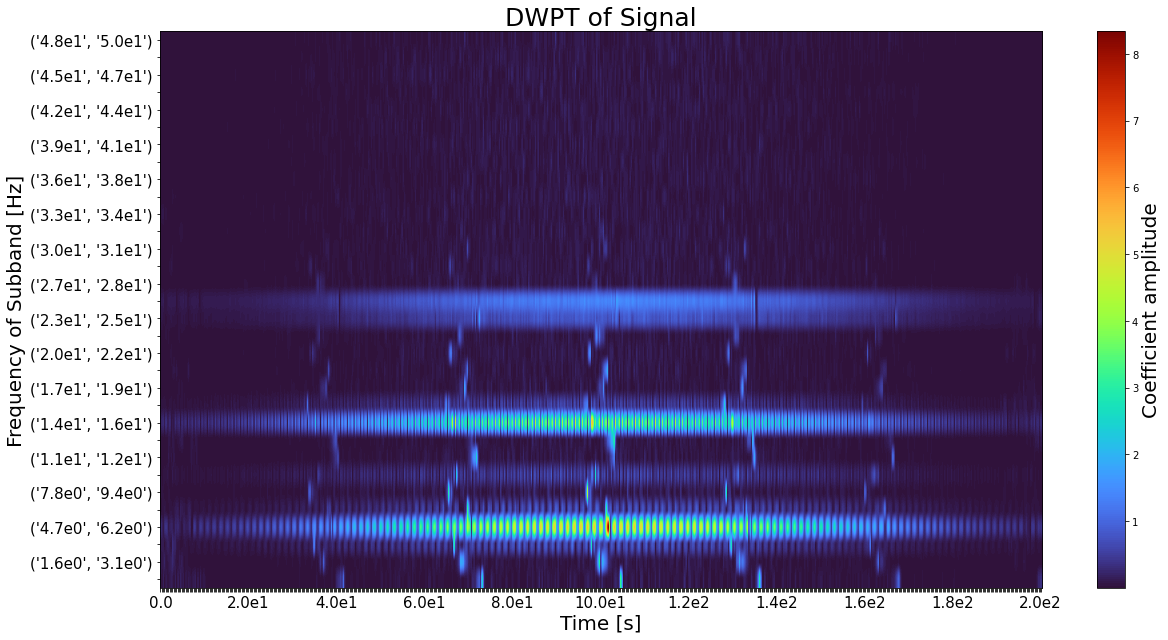

In [9]:
plot.heisenberg(tr_ob, max(t_plot))

### Clustering

k-means clustering algorithm with energy, kurtosis, and crest factor as the input

In [10]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
data_train = []
for node, inverse, _, energy, kurtosis, crest, entropy in rec:
    data_train.append(
        (energy, kurtosis, crest, entropy)
        )

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 5
kmeans = KMeans(n_clusters=no_clusters)
kmeans.fit(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

### plot result

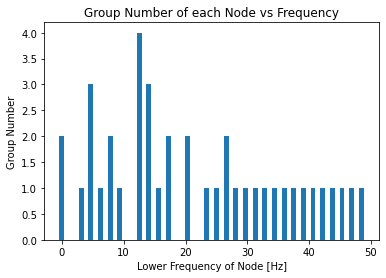

Cluster labels: [2 0 1 3 1 2 1 0 4 3 1 2 0 2 0 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
highest energy: 3
highest kurtosis: 4
highest crest factor: 4


In [11]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node,*_ in rec], labels)
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

print("Cluster labels:", labels)
print(f"highest energy: {np.argmax(centers[:,0])}")
print(f'highest kurtosis: {np.argmax(centers[:,1])}')
print(f'highest crest factor: {np.argmax(centers[:,2])}')

### PCA

In [12]:
# apply PCA to training data
pca = PCA(n_components=3)
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters)
kmeans_pca.fit(data_pca)

labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(pca.inverse_transform(kmeans_pca.cluster_centers_))

### Plot PCA Result

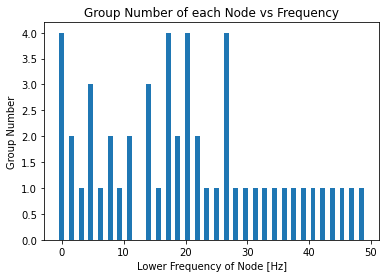

Eigenvectors:
Energy, Kurtosis, Crest factor, Peak, Mean
[[-0.21  0.56  0.57 -0.57]
 [ 0.97  0.19  0.08 -0.08]
 [-0.08  0.8  -0.34  0.48]]
Eigenvalues: [3.03 0.95 0.08]
Cluster labels: [4 2 1 3 1 2 1 2 0 3 1 4 2 4 2 1 1 4 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
highest PC1: 3
highest PC2: 0
highest PC3: 0


In [13]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node,*_ in rec]
plt.bar([node.frequency_range[0] for node,*_ in rec], labels_pca)
plt.tick_params
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print('Energy, Kurtosis, Crest factor, Peak, Mean')
print(np.round(eigenvectors,2))

print("Eigenvalues:", np.round(eigenvalues,2))

print("Cluster labels:", labels_pca)
print(f"highest PC1: {np.argmax(centers_pca[:,0])}")
print(f'highest PC2: {np.argmax(centers_pca[:,1])}')
print(f'highest PC3: {np.argmax(centers_pca[:,2])}')

### 3d plot

3d plots of the results with axes energy, kurtosis, crest factor

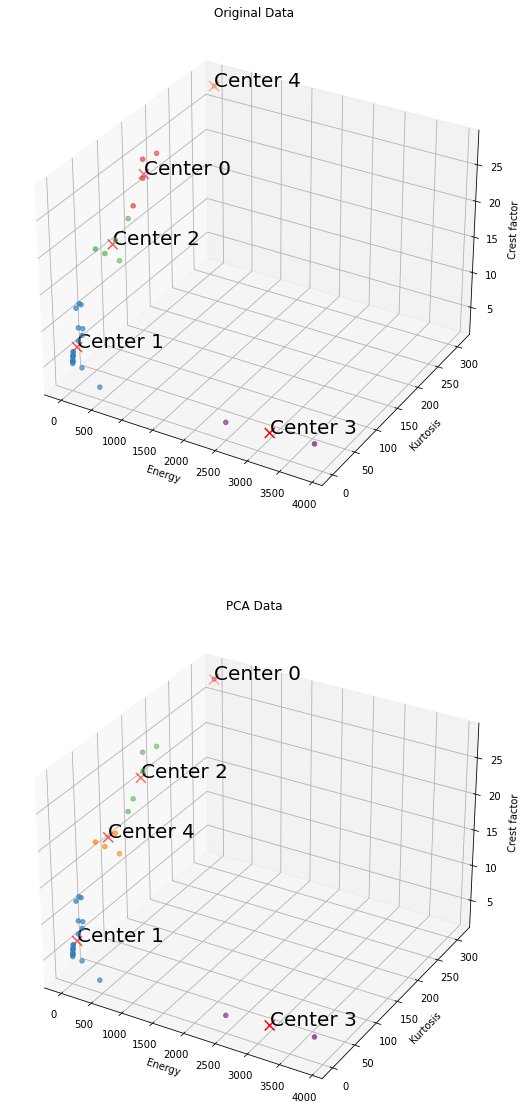

In [14]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={'projection': '3d'})

titles = ['Original Data', 'PCA Data']

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap('Set1')
    if i == 0:
        data_scatter = data_train
        centers_scatter = centers
        labels_scatter = labels
    else:
        data_scatter = data_train
        centers_scatter = centers_pca
        labels_scatter = labels_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        c=[cmap(label) for label in labels_scatter])
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c='red', marker='x', s=100)
    
    ax.set_xlabel('Energy')
    ax.set_ylabel('Kurtosis')
    ax.set_zlabel('Crest factor')
    ax.set_title(titles[i])

    # Annotate cluster centers with their positions
    for i, center in enumerate(centers_scatter):
        ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

plt.show()

### 2d plot

plots with energy vs crest factor comparing PCA and no PCA results

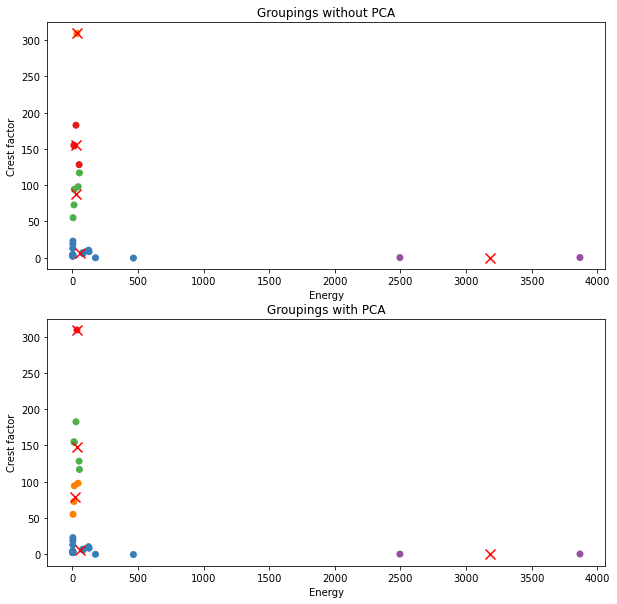

In [15]:
# 3d plot
fig, ax = plt.subplots(2,figsize=(10,10))

# plot with colours for each cluster
cmap = plt.cm.get_cmap('Set1')
x = 0  # 0 -> energy, 1 -> kurtosis, 3 -> crest
y = 1  # ""
data_scatter = data_train
labels_scatter = labels
ax[0].scatter(
    [point[x] for point in data_scatter],
    [point[y] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
labels_scatter = labels_pca
ax[1].scatter(
    [point[x] for point in data_scatter],
    [point[y] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
# plot centres
centers_scatter = centers
ax[0].scatter(centers_scatter[:, x], 
           centers_scatter[:, y], c='red', marker='x', s=100)
centers_scatter = centers_pca
ax[1].scatter(centers_scatter[:, x], 
           centers_scatter[:, y], c='red', marker='x', s=100)
for i in range(2):
    ax[i].set_xlabel('Energy')
    ax[i].set_ylabel('Crest factor')
ax[0].set_title('Groupings without PCA')
ax[1].set_title('Groupings with PCA')
plt.show()

### Results

Plotting the reconstructed waves from clustering with their assigned group

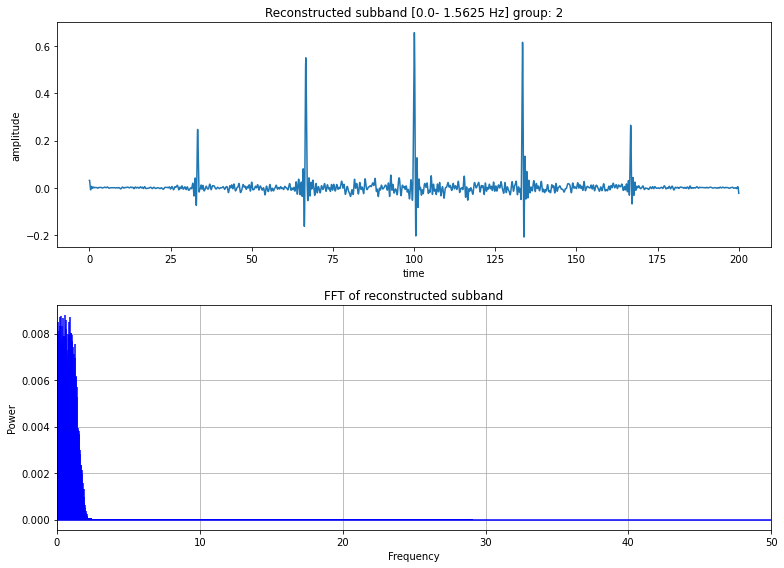

energy of recovered signal: 43.925880923945996
kurtosis of recovered signal: 97.89711758359856
crest factor of recovered signal: 14.032440897279036
entropy of recovered signal: 5.907334480221657

energy of node coefficients: 44.59201175043387
kurtosis of node coefficients: 98.22034412883937
crest factor of node coefficients: 13.777183331654248
entropy of node coefficinets: 2.661546443170404


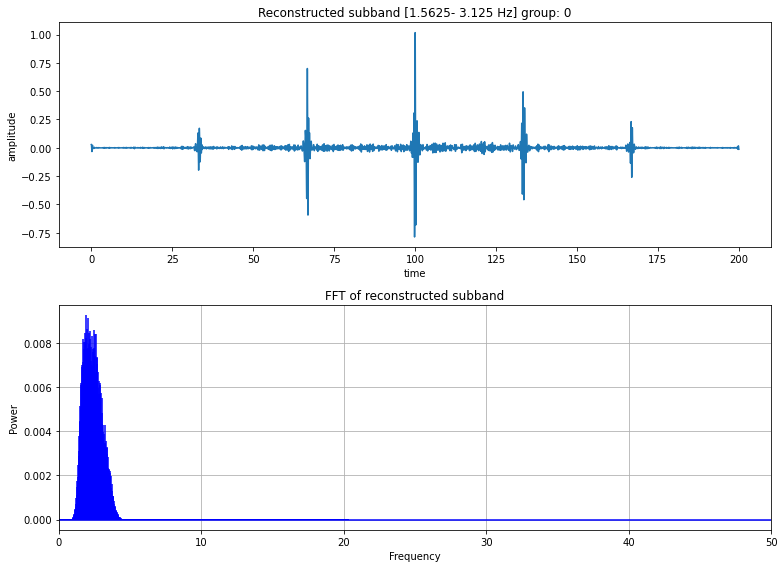

energy of recovered signal: 51.3041894875861
kurtosis of recovered signal: 128.33611539615677
crest factor of recovered signal: 20.076771133295892
entropy of recovered signal: 5.830164413773231

energy of node coefficients: 51.62722312920987
kurtosis of node coefficients: 46.03636771679885
crest factor of node coefficients: 10.892464326493744
entropy of node coefficinets: 3.244990304426567


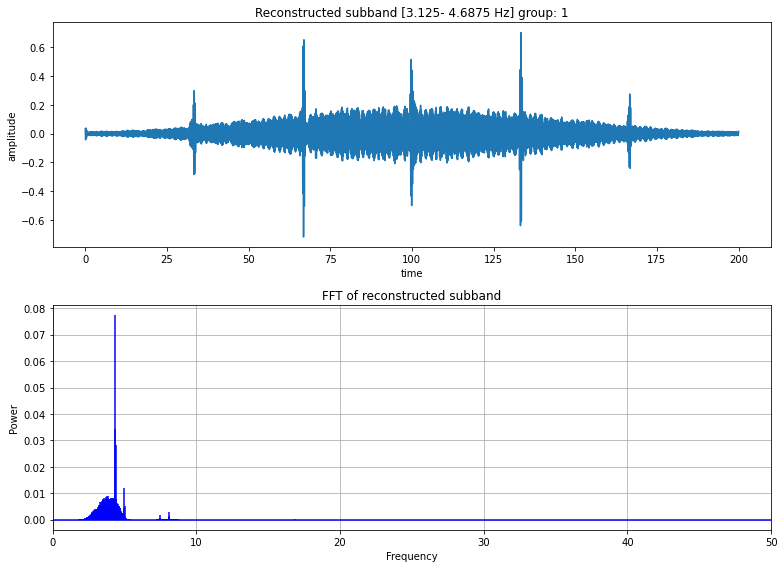

energy of recovered signal: 127.60870545751911
kurtosis of recovered signal: 8.230939443572145
crest factor of recovered signal: 8.779040470744325
entropy of recovered signal: 8.623811036610729

energy of node coefficients: 127.95969006075973
kurtosis of node coefficients: 12.58169331156593
crest factor of node coefficients: 6.1310525180119155
entropy of node coefficinets: 5.141017731363917


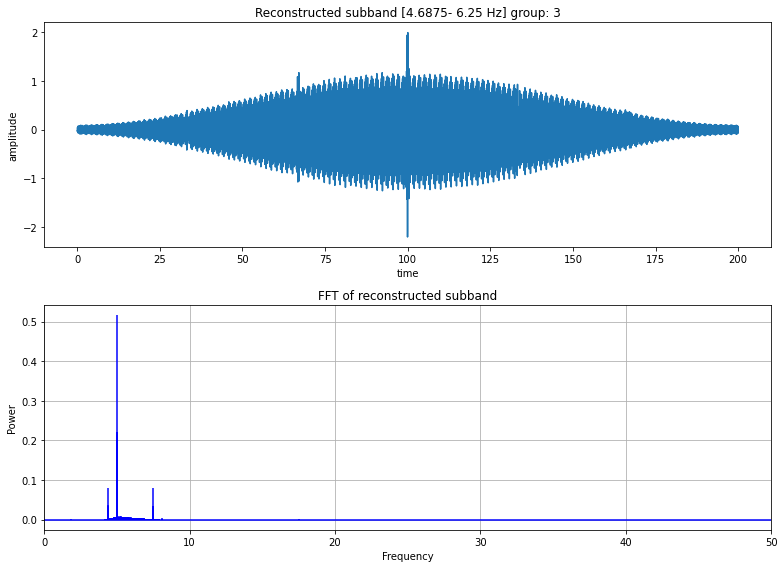

energy of recovered signal: 3869.1450000031323
kurtosis of recovered signal: 0.1745302782348528
crest factor of recovered signal: 4.532648625384639
entropy of recovered signal: 9.067170826280613

energy of node coefficients: 3871.3884853632535
kurtosis of node coefficients: 3.0699915731870946
crest factor of node coefficients: 3.0032957272373526
entropy of node coefficinets: 5.653421722287362


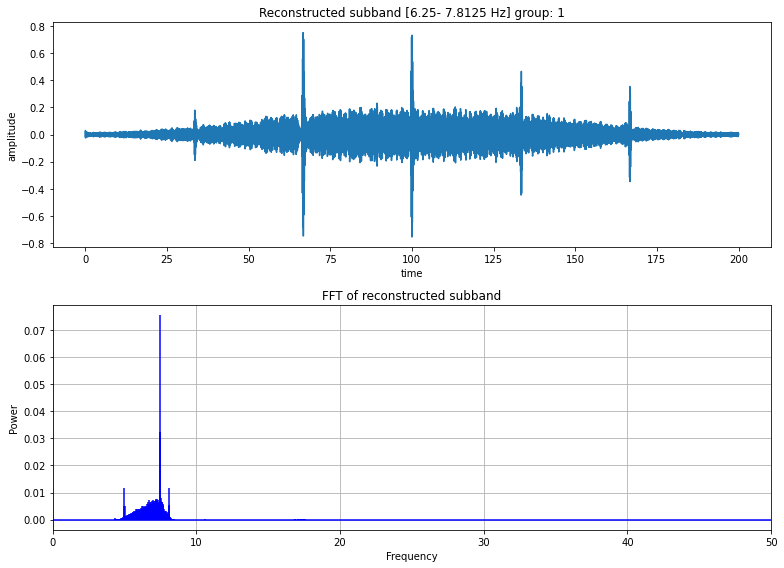

energy of recovered signal: 123.58086883713165
kurtosis of recovered signal: 10.334758056520542
crest factor of recovered signal: 9.569666939220305
entropy of recovered signal: 8.570226584165033

energy of node coefficients: 123.77835874515388
kurtosis of node coefficients: 12.106143158108479
crest factor of node coefficients: 7.258362067438469
entropy of node coefficinets: 5.18039246939659


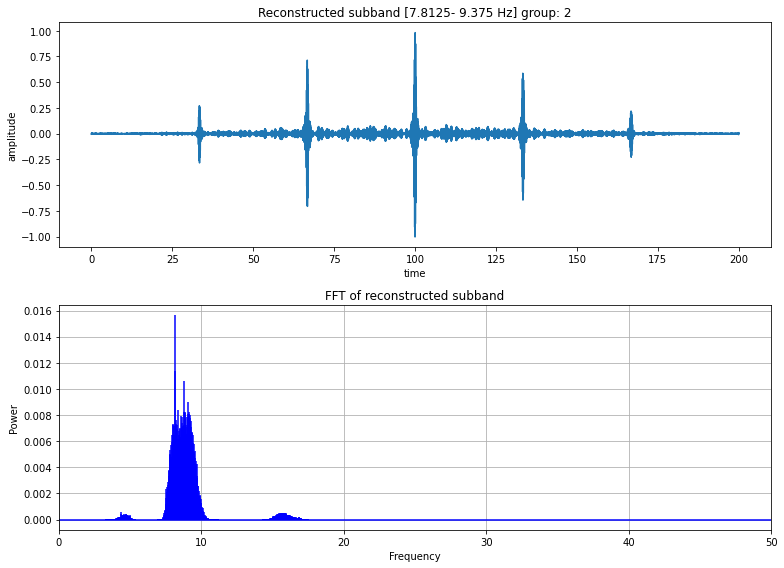

energy of recovered signal: 53.86635043451054
kurtosis of recovered signal: 116.87462997321654
crest factor of recovered signal: 18.912632463717724
entropy of recovered signal: 6.099709604885647

energy of node coefficients: 53.89408852372793
kurtosis of node coefficients: 134.39197721089684
crest factor of node coefficients: 15.492181784329167
entropy of node coefficinets: 2.487575238143477


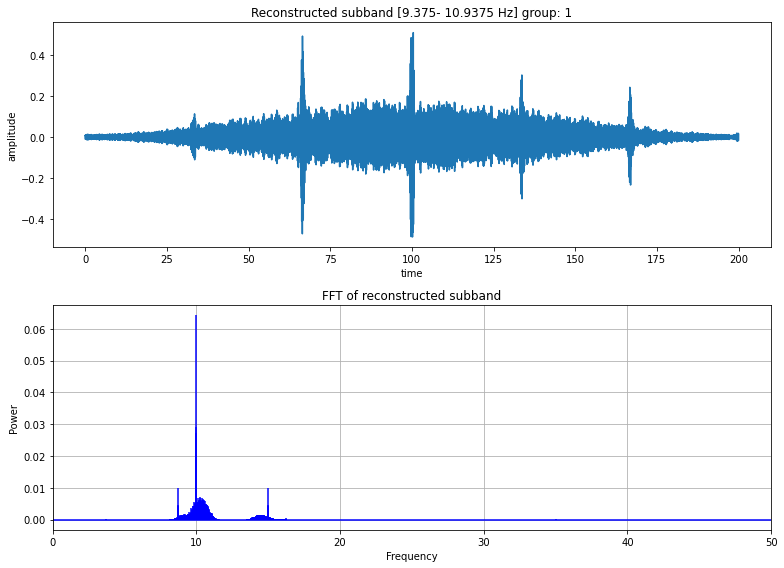

energy of recovered signal: 81.39630227816393
kurtosis of recovered signal: 5.709026414457345
crest factor of recovered signal: 8.018812817370192
entropy of recovered signal: 8.699828974422225

energy of node coefficients: 81.5025590154496
kurtosis of node coefficients: 10.710009368524084
crest factor of node coefficients: 6.993380263519236
entropy of node coefficinets: 5.229292099147536


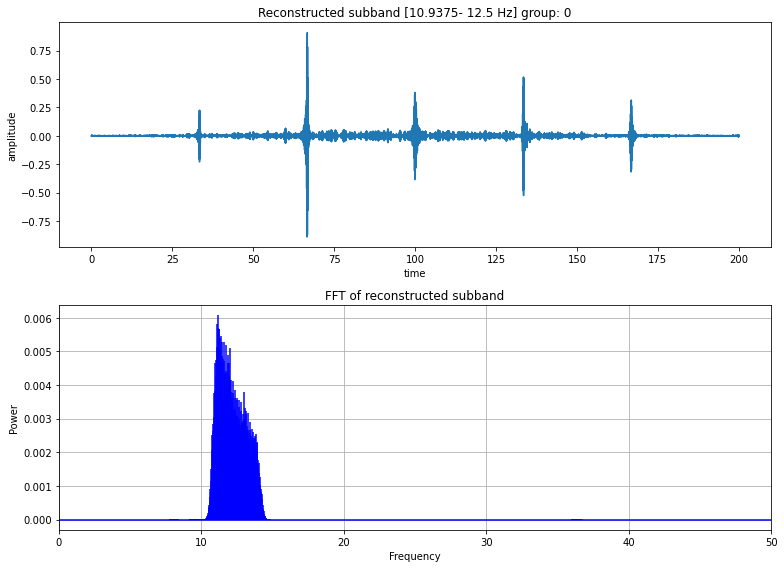

energy of recovered signal: 27.394554074754495
kurtosis of recovered signal: 182.7370428947918
crest factor of recovered signal: 24.526861564823356
entropy of recovered signal: 5.802876914912205

energy of node coefficients: 27.452563256102124
kurtosis of node coefficients: 66.09190374663031
crest factor of node coefficients: 12.257739730962502
entropy of node coefficinets: 3.0576790991968616


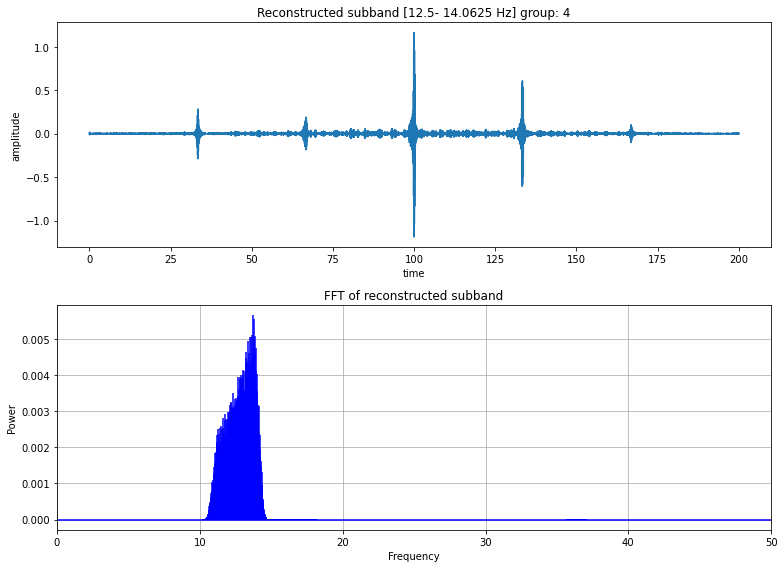

energy of recovered signal: 34.83801320048446
kurtosis of recovered signal: 309.36115393297104
crest factor of recovered signal: 27.85162774385671
entropy of recovered signal: 5.169751651945786

energy of node coefficients: 35.00140827727526
kurtosis of node coefficients: 99.77218771958196
crest factor of node coefficients: 10.122693644358293
entropy of node coefficinets: 2.673212734462863


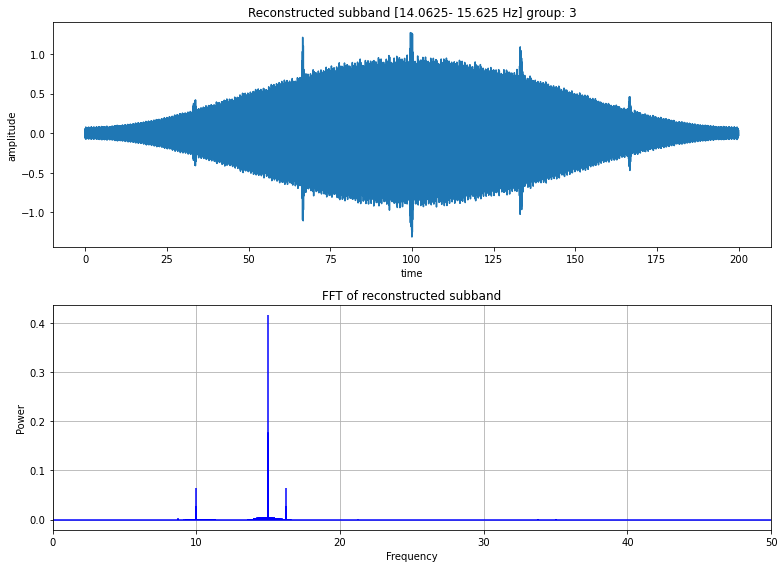

energy of recovered signal: 2496.8678855446474
kurtosis of recovered signal: 0.0729896381384676
crest factor of recovered signal: 3.598460121776519
entropy of recovered signal: 9.074672532572508

energy of node coefficients: 2498.5385961502584
kurtosis of node coefficients: 2.952545385679139
crest factor of node coefficients: 2.887338950713191
entropy of node coefficinets: 5.6624172296449915


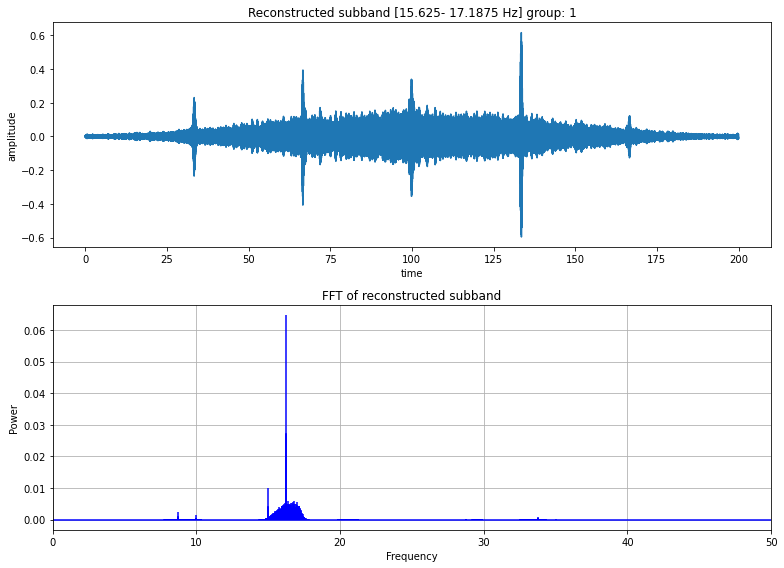

energy of recovered signal: 79.44542926831471
kurtosis of recovered signal: 6.794091614350005
crest factor of recovered signal: 9.778192872750646
entropy of recovered signal: 8.708029186579806

energy of node coefficients: 79.66790325783232
kurtosis of node coefficients: 8.091953587542795
crest factor of node coefficients: 4.380920314740578
entropy of node coefficinets: 5.339726040781878


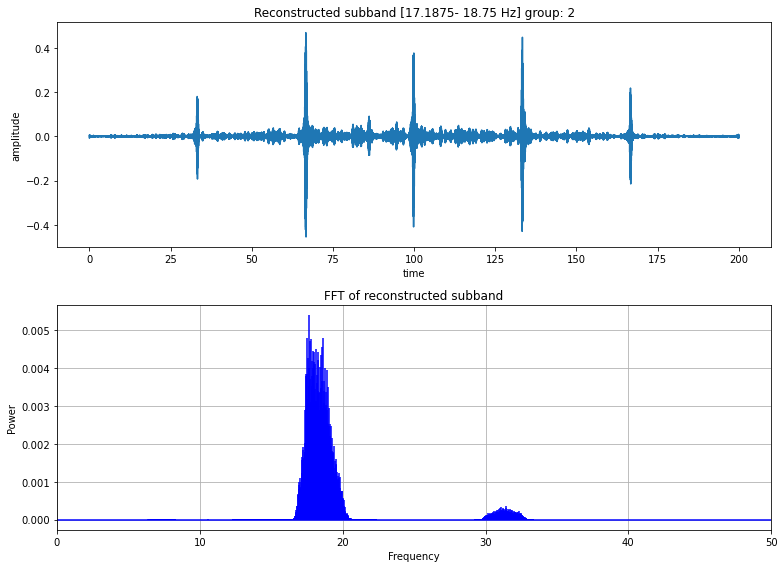

energy of recovered signal: 15.188398230869078
kurtosis of recovered signal: 94.29080999545296
crest factor of recovered signal: 17.002660848358722
entropy of recovered signal: 6.309340408595421

energy of node coefficients: 15.232050373432301
kurtosis of node coefficients: 73.68512603429508
crest factor of node coefficients: 4.239561495041363
entropy of node coefficinets: 3.179681319187154


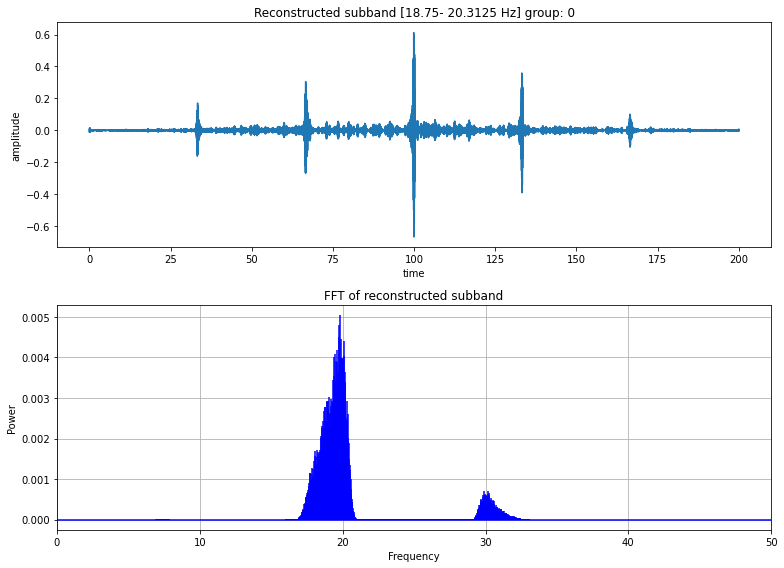

energy of recovered signal: 14.823016726325886
kurtosis of recovered signal: 154.20141560239975
crest factor of recovered signal: 22.489008607362226
entropy of recovered signal: 6.105412639454105

energy of node coefficients: 14.86867374901287
kurtosis of node coefficients: 68.41571904545603
crest factor of node coefficients: 6.8994515769740605
entropy of node coefficinets: 3.2014601076036806


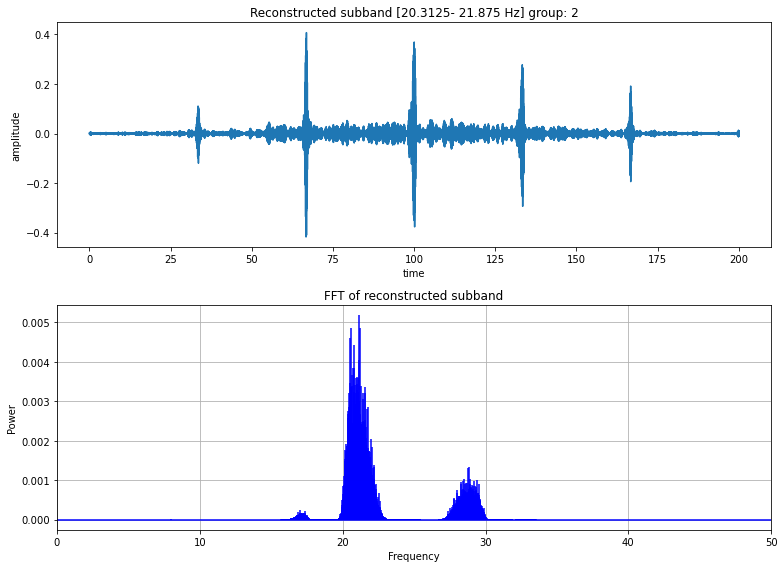

energy of recovered signal: 12.50997411851338
kurtosis of recovered signal: 72.75696515785972
crest factor of recovered signal: 16.293839503327575
entropy of recovered signal: 6.6952956727473465

energy of node coefficients: 12.56508732310623
kurtosis of node coefficients: 62.324256599302515
crest factor of node coefficients: 8.917438711892268
entropy of node coefficinets: 3.3224723497641686


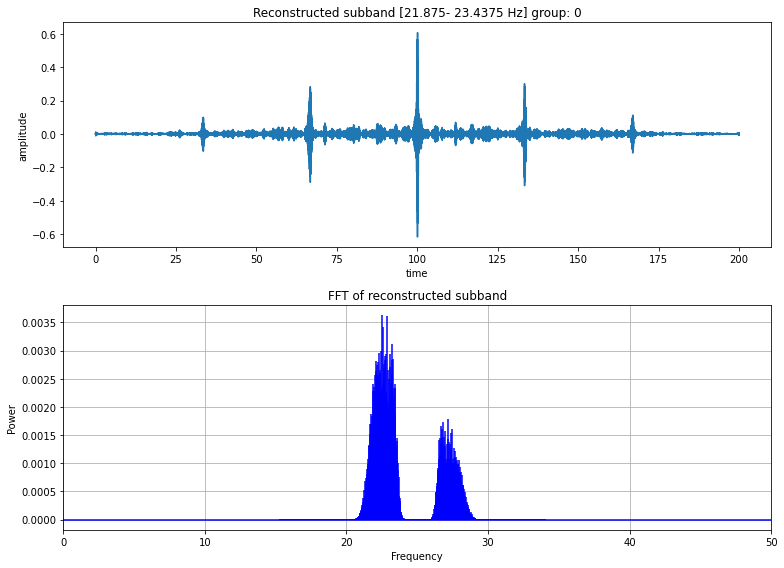

energy of recovered signal: 11.738070318139687
kurtosis of recovered signal: 155.16416818232753
crest factor of recovered signal: 25.03543240647425
entropy of recovered signal: 6.2711792661257375

energy of node coefficients: 11.773304021610825
kurtosis of node coefficients: 44.67308579385254
crest factor of node coefficients: 11.16824664228806
entropy of node coefficinets: 3.6385960799897106


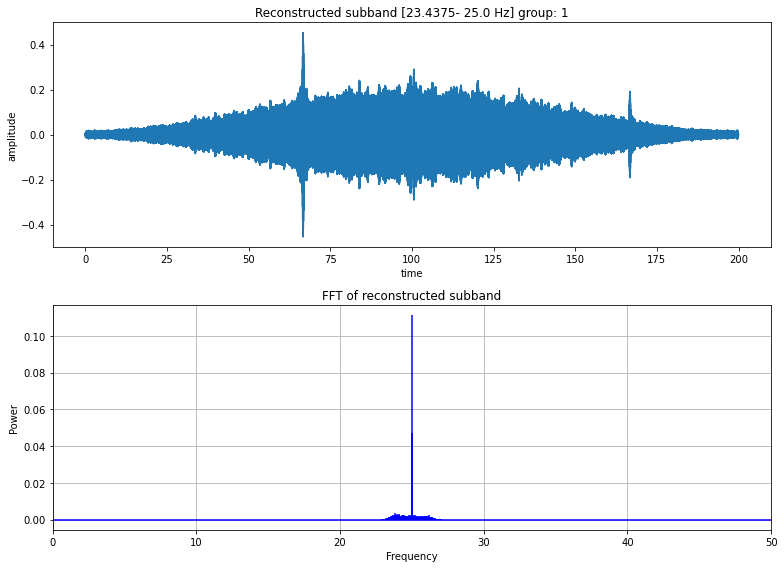

energy of recovered signal: 176.01017895394202
kurtosis of recovered signal: -0.19671917039938602
crest factor of recovered signal: 4.826965454546123
entropy of recovered signal: 9.220127657282307

energy of node coefficients: 176.19737058850708
kurtosis of node coefficients: 2.6553714635591144
crest factor of node coefficients: 1.4682831354836698
entropy of node coefficinets: 5.916191532642388


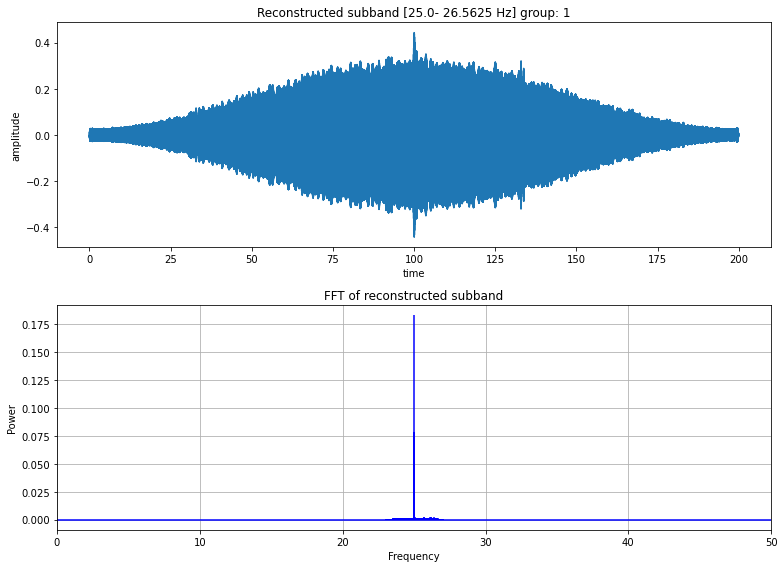

energy of recovered signal: 465.2274819058887
kurtosis of recovered signal: -0.5644869625771891
crest factor of recovered signal: 2.9049695706419874
entropy of recovered signal: 9.266511793584314

energy of node coefficients: 465.63236041394936
kurtosis of node coefficients: 1.6217763067768742
crest factor of node coefficients: 0.23866733224408784
entropy of node coefficinets: 5.954153874867819


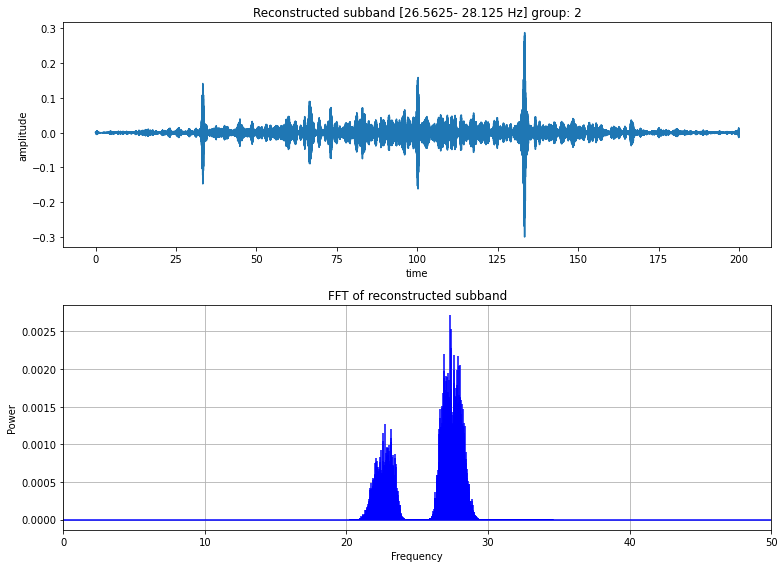

energy of recovered signal: 5.201774367720349
kurtosis of recovered signal: 55.027774036299
crest factor of recovered signal: 17.841490954426238
entropy of recovered signal: 7.489796005443693

energy of node coefficients: 5.2314587661617695
kurtosis of node coefficients: 23.394980003170197
crest factor of node coefficients: 6.558477471298959
entropy of node coefficinets: 4.530053318772029


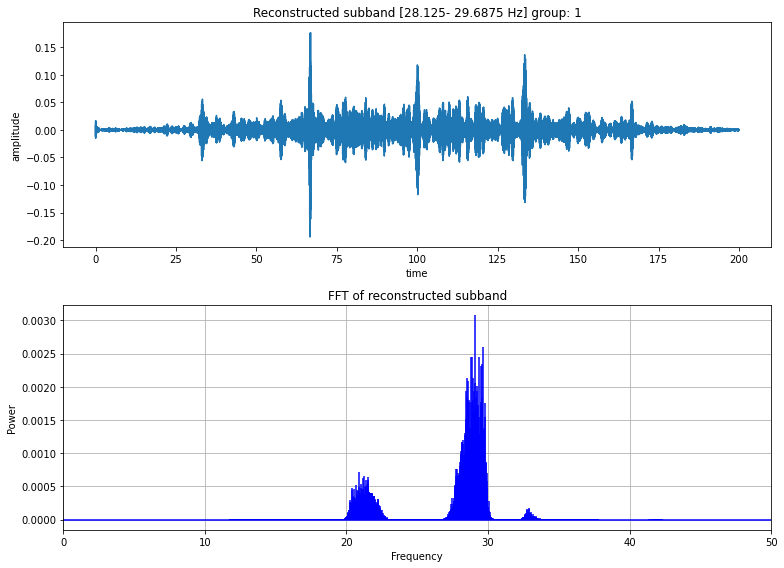

energy of recovered signal: 4.138505975225981
kurtosis of recovered signal: 18.833374549118215
crest factor of recovered signal: 12.265025434090024
entropy of recovered signal: 8.077531672941884

energy of node coefficients: 4.148461850496359
kurtosis of node coefficients: 15.916108860606608
crest factor of node coefficients: 8.406541303143932
entropy of node coefficinets: 4.817133600326424


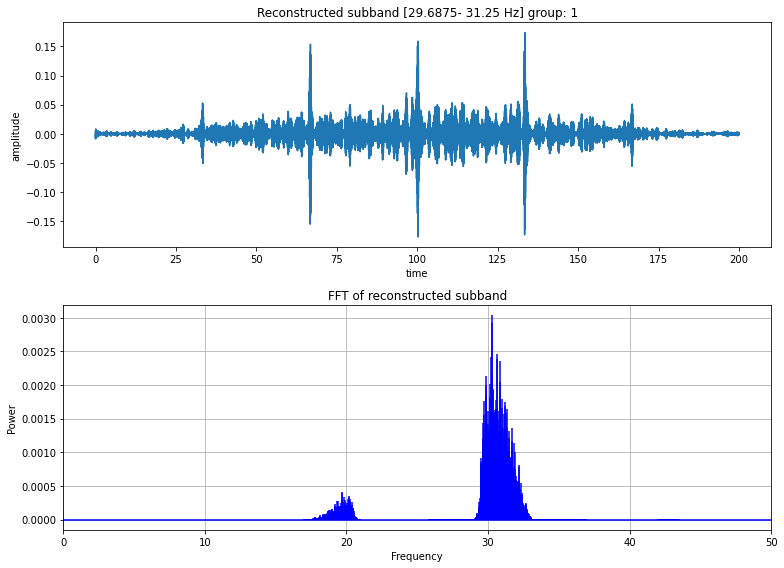

energy of recovered signal: 4.252894317155017
kurtosis of recovered signal: 22.829381629813753
crest factor of recovered signal: 11.903994505126054
entropy of recovered signal: 7.9516218556811396

energy of node coefficients: 4.260247825993327
kurtosis of node coefficients: 19.798724038226975
crest factor of node coefficients: 8.069428766757696
entropy of node coefficinets: 4.685239276695794


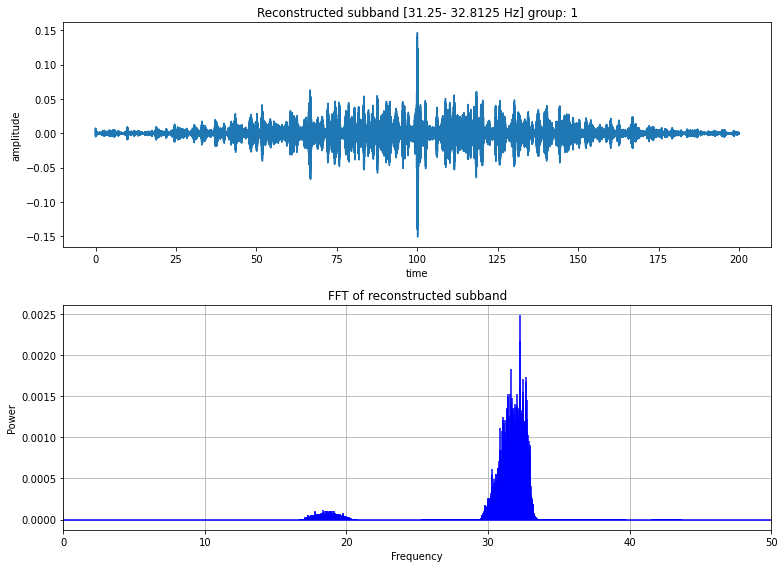

energy of recovered signal: 3.001571121495317
kurtosis of recovered signal: 12.861943992446031
crest factor of recovered signal: 11.974121650489273
entropy of recovered signal: 8.304509528999008

energy of node coefficients: 3.0128899845822756
kurtosis of node coefficients: 8.410726903244045
crest factor of node coefficients: 3.9626785333320456
entropy of node coefficinets: 5.066054307246908


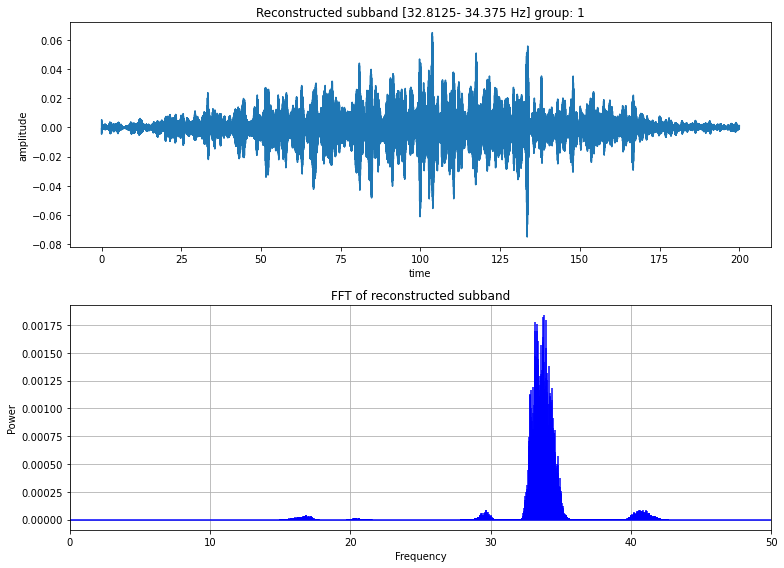

energy of recovered signal: 2.4752613110987496
kurtosis of recovered signal: 3.4714587762987206
crest factor of recovered signal: 5.848025884284559
entropy of recovered signal: 8.658869198986205

energy of node coefficients: 2.4929970756249906
kurtosis of node coefficients: 7.426280147837532
crest factor of node coefficients: 5.331717422310008
entropy of node coefficinets: 5.162787954170769


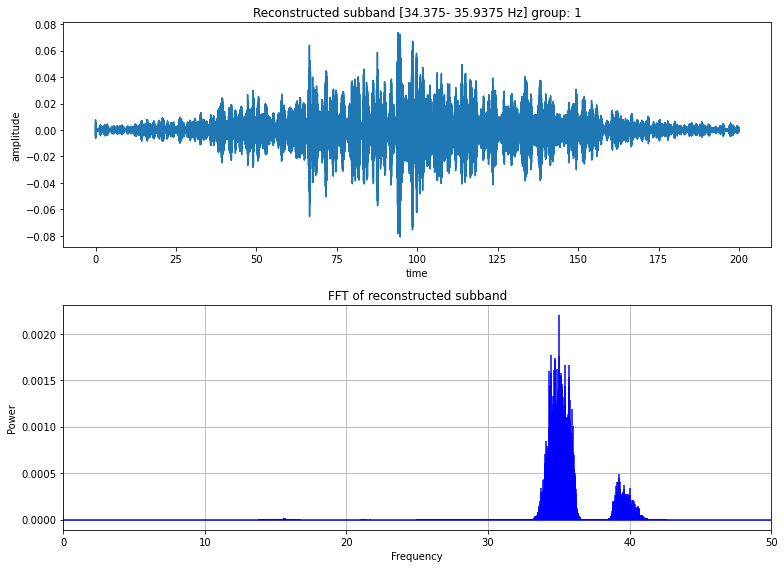

energy of recovered signal: 2.654596622266195
kurtosis of recovered signal: 4.178792773535782
crest factor of recovered signal: 6.388434669229028
entropy of recovered signal: 8.582465455302609

energy of node coefficients: 2.661380101302448
kurtosis of node coefficients: 5.706897983740199
crest factor of node coefficients: 4.131736036627388
entropy of node coefficinets: 5.251332980840079


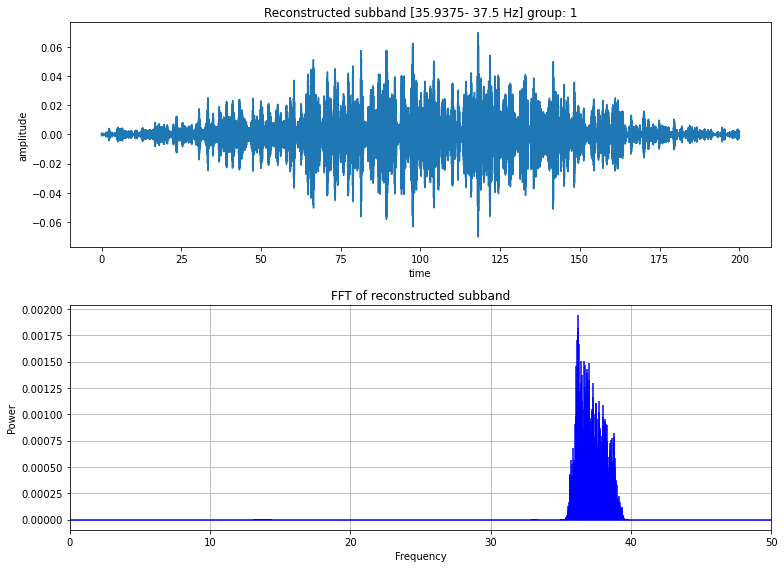

energy of recovered signal: 2.4083049407691535
kurtosis of recovered signal: 3.807825034657651
crest factor of recovered signal: 6.369886848210664
entropy of recovered signal: 8.54923778852157

energy of node coefficients: 2.4112655402161582
kurtosis of node coefficients: 5.988652232910357
crest factor of node coefficients: 3.4376859192426656
entropy of node coefficinets: 5.220555407382746


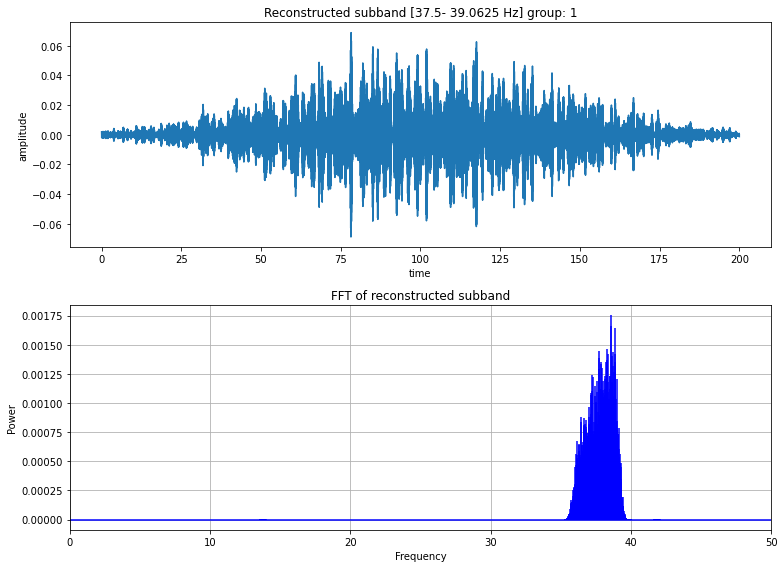

energy of recovered signal: 2.6630570545137173
kurtosis of recovered signal: 3.7512598620484523
crest factor of recovered signal: 5.967510420839069
entropy of recovered signal: 8.5489334142182

energy of node coefficients: 2.664343966787899
kurtosis of node coefficients: 5.2681343343160245
crest factor of node coefficients: 3.95237626220853
entropy of node coefficinets: 5.3030299926873194


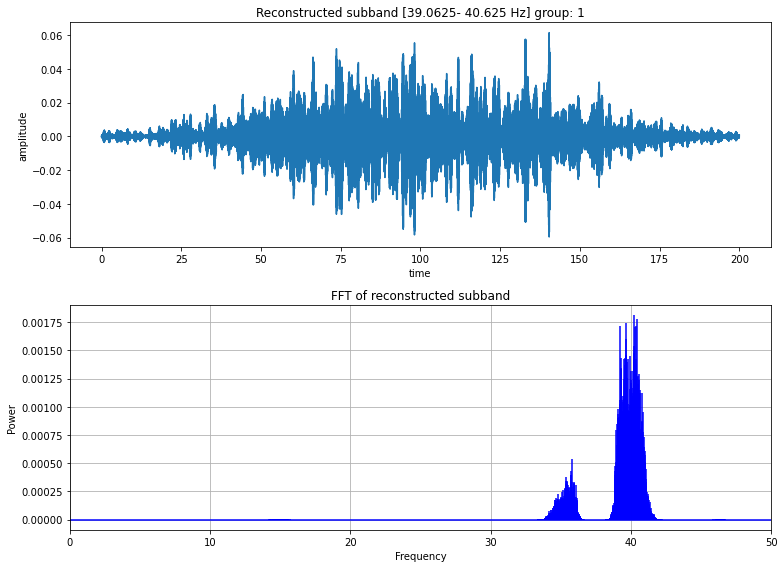

energy of recovered signal: 2.402860529958235
kurtosis of recovered signal: 2.870118886043529
crest factor of recovered signal: 5.610151781398377
entropy of recovered signal: 8.658238446132685

energy of node coefficients: 2.404397353714851
kurtosis of node coefficients: 6.052158095531532
crest factor of node coefficients: 3.6410269140090725
entropy of node coefficinets: 5.204391656766899


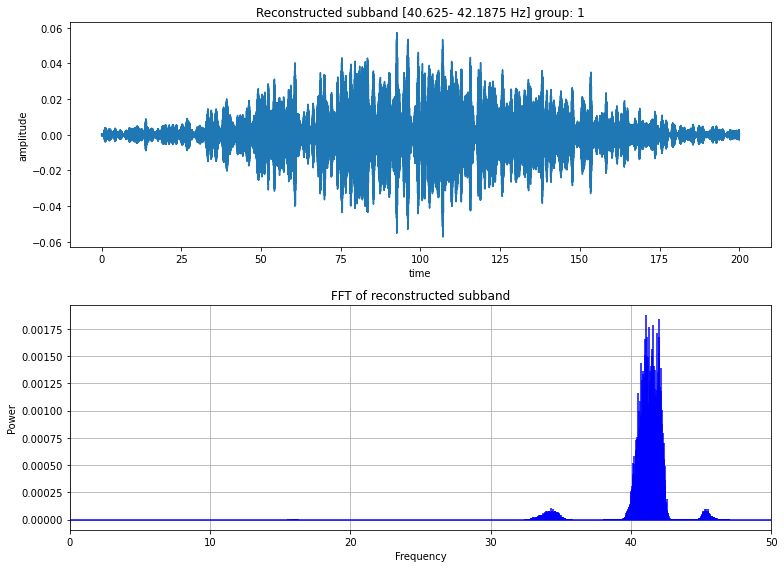

energy of recovered signal: 2.551406583551961
kurtosis of recovered signal: 2.1213050921810686
crest factor of recovered signal: 5.070099619254288
entropy of recovered signal: 8.72644408952099

energy of node coefficients: 2.553312486885164
kurtosis of node coefficients: 5.0827428629186615
crest factor of node coefficients: 3.8490837971459
entropy of node coefficinets: 5.303836882734196


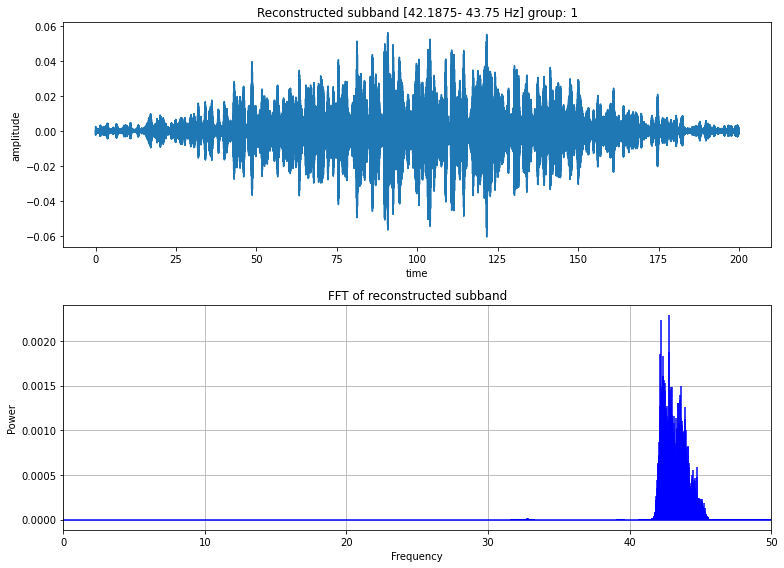

energy of recovered signal: 2.5018622061091764
kurtosis of recovered signal: 2.5060235873178955
crest factor of recovered signal: 5.026509053305064
entropy of recovered signal: 8.70482185577904

energy of node coefficients: 2.504482111717622
kurtosis of node coefficients: 4.400385659745705
crest factor of node coefficients: 3.457066542991734
entropy of node coefficinets: 5.400464332604529


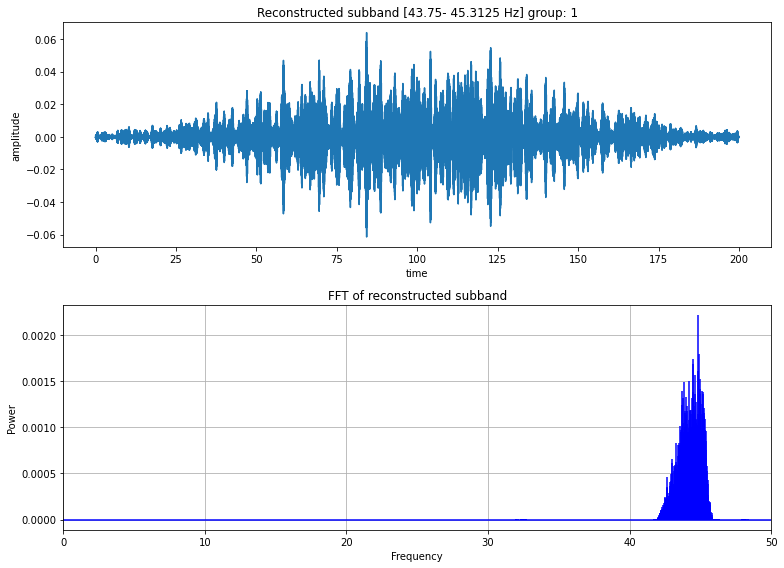

energy of recovered signal: 2.409751663844812
kurtosis of recovered signal: 2.8575398977309003
crest factor of recovered signal: 5.827467145387081
entropy of recovered signal: 8.640169506102318

energy of node coefficients: 2.411906045541341
kurtosis of node coefficients: 5.531704651928011
crest factor of node coefficients: 3.953096442998832
entropy of node coefficinets: 5.267455873405742


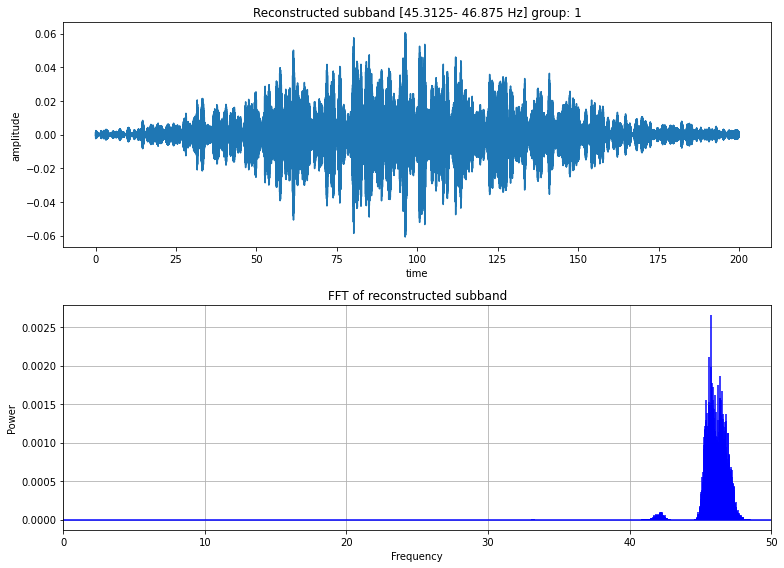

energy of recovered signal: 2.7273021456475046
kurtosis of recovered signal: 2.521465653803136
crest factor of recovered signal: 5.186800983204785
entropy of recovered signal: 8.690729472982161

energy of node coefficients: 2.729347125005764
kurtosis of node coefficients: 5.976036158085386
crest factor of node coefficients: 5.179106042472421
entropy of node coefficinets: 5.223451351109648


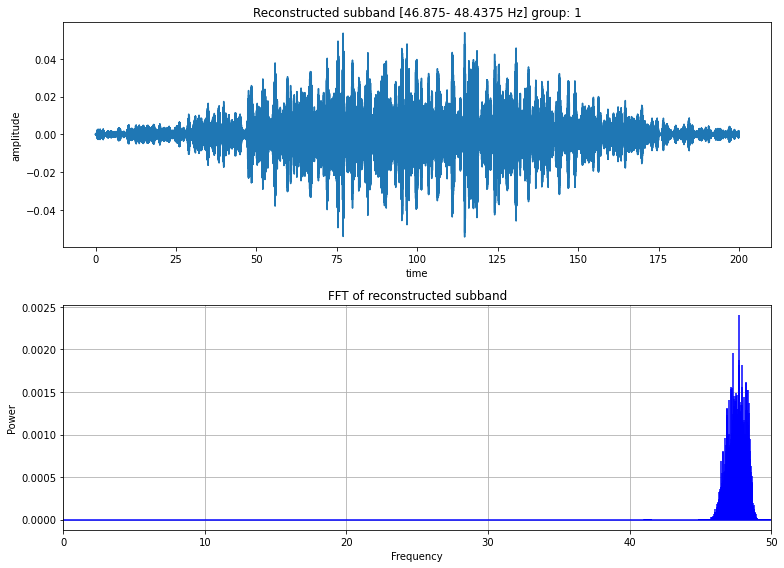

energy of recovered signal: 2.5172483671384907
kurtosis of recovered signal: 2.2195460021469673
crest factor of recovered signal: 4.809316631727978
entropy of recovered signal: 8.732069943261191

energy of node coefficients: 2.519580816031267
kurtosis of node coefficients: 5.20450951360769
crest factor of node coefficients: 3.441388657537182
entropy of node coefficinets: 5.279591659707125


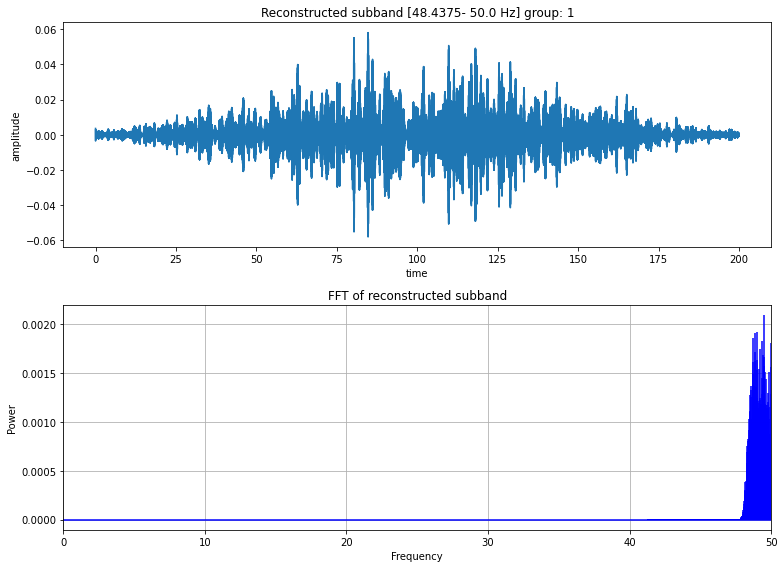

energy of recovered signal: 2.475530856970284
kurtosis of recovered signal: 2.859317552757692
crest factor of recovered signal: 5.216921467593606
entropy of recovered signal: 8.702542460164425

energy of node coefficients: 2.480974565385067
kurtosis of node coefficients: 5.401475160570657
crest factor of node coefficients: 5.3568343765774475
entropy of node coefficinets: 5.332637217459716


array([-0.00054926,  0.02208617,  0.13812005, ..., -0.04989792,
       -0.04150657, -0.01137319])

In [16]:
plot_reconstructions(rec, group=labels)

# Appendix

### kurtosis and crest factor calculations
testing kurtosis and crest factor calculations on wavelet packet coefficients and reconstructed waves

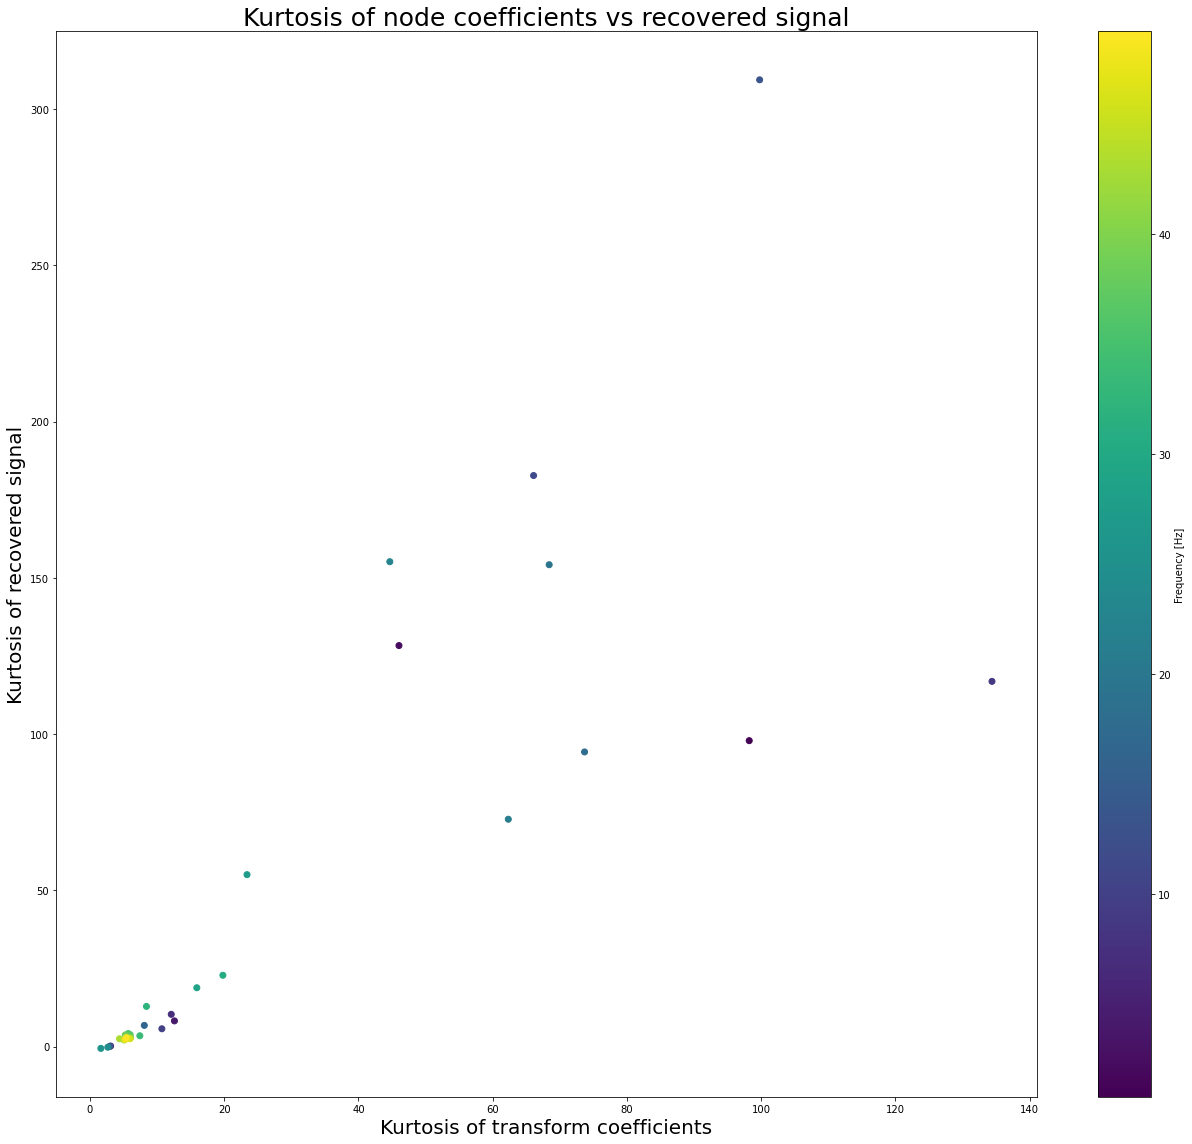

In [17]:
# Calculate frequenciens for plotting
cent_freqs = [
    round(1 / 2 * sum(node.frequency_range), 1)
    for node in tr_ob.get_level(order="freq")
]
cent_freqs = np.array(cent_freqs)
sparse_cent_freqs = [
    cent_freq if id % 1 == 0 else "" for id, cent_freq in enumerate(cent_freqs)
]

# Gather data
coef_kurtosis = [node.kurtosis for node, *_ in rec]
kurtosis = [sc.kurtosis(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_kurtosis, kurtosis, c=cent_freqs)
ax.set_title("Kurtosis of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Kurtosis of transform coefficients", fontsize=20)
ax.set_ylabel("Kurtosis of recovered signal", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()

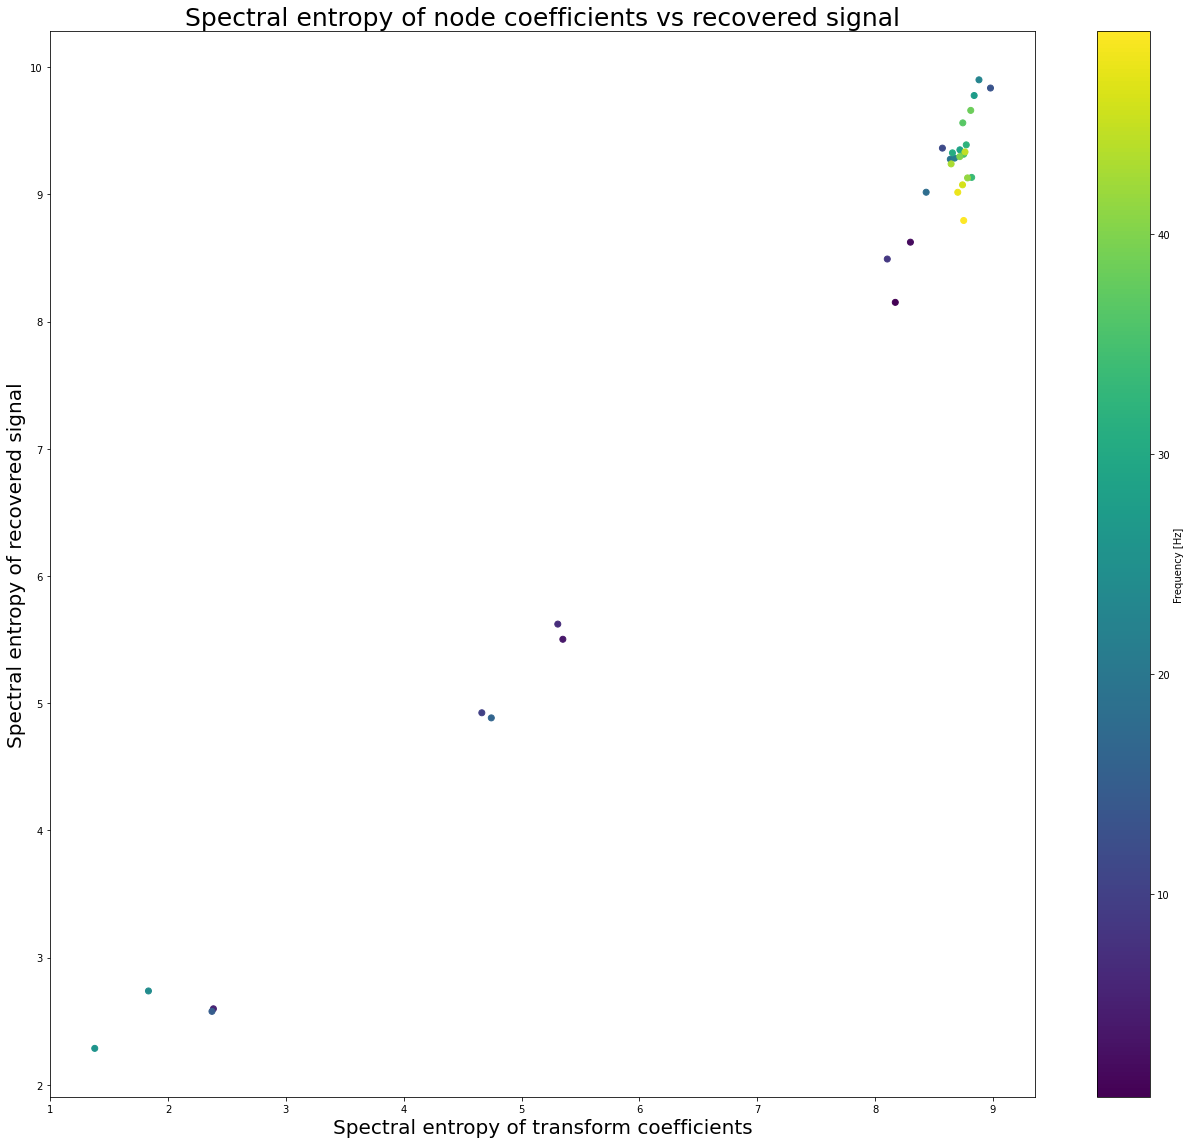

In [21]:
# gather data
coef_spectral_entropy = [node.spectral_entropy for node, *_ in rec]
rec_spectral_entropy = [stats.spectral_entropy(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_spectral_entropy, rec_spectral_entropy, c=cent_freqs)
ax.set_title("Spectral entropy of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Spectral entropy of transform coefficients", fontsize=20)
ax.set_ylabel("Spectral entropy of recovered signal", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()

(<wavelet_transform.wpt.transform_node.Node object at 0x0000021D84D59DF0>, array([ 0.02664881,  0.02686381,  0.02693537, ..., -0.0171618 ,
       -0.01865206, -0.02018222]), array([ 7.91894584e-03+0.00000000e+00j, -3.37913287e-03-1.07183569e-04j,
       -7.61805537e-04+8.78787360e-05j, ...,
        2.37311856e-06-1.14098799e-09j,  2.37311857e-06-7.60658627e-10j,
        2.37311857e-06-3.80329304e-10j]), 0.0022555317877427507, 98.49941417362042, 1.7935034566800343, 5.913895286311434)


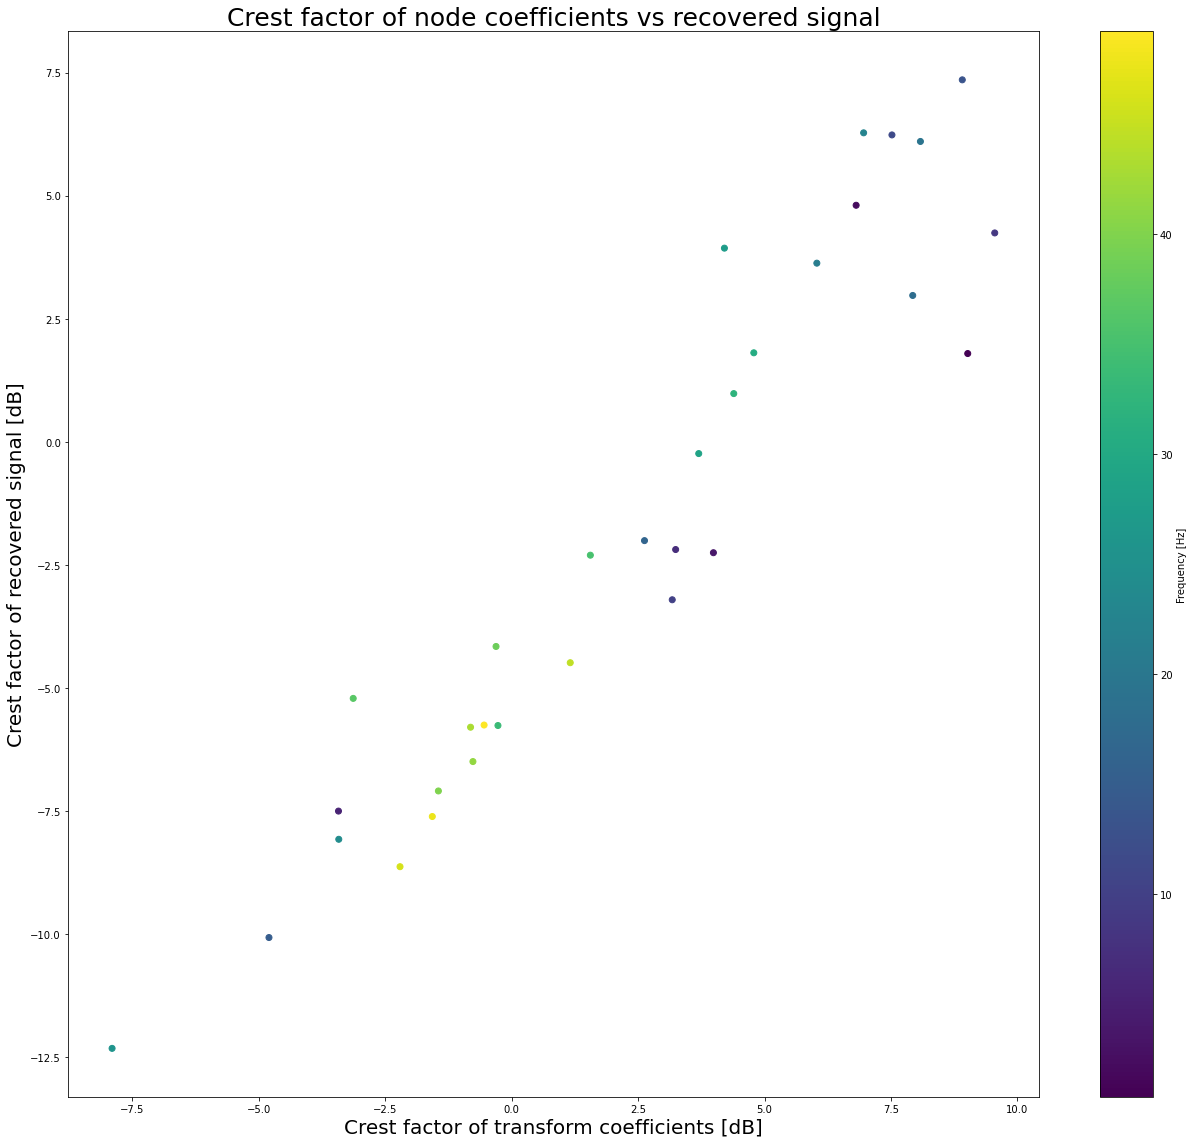

In [40]:
# gather data
coef_crest = [node.crest_factor for node, *_ in rec]
crest = [stats.crest_factor(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_crest, crest, c=cent_freqs)
ax.set_title("Crest factor of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Crest factor of transform coefficients [dB]", fontsize=20)
ax.set_ylabel("Crest factor of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()

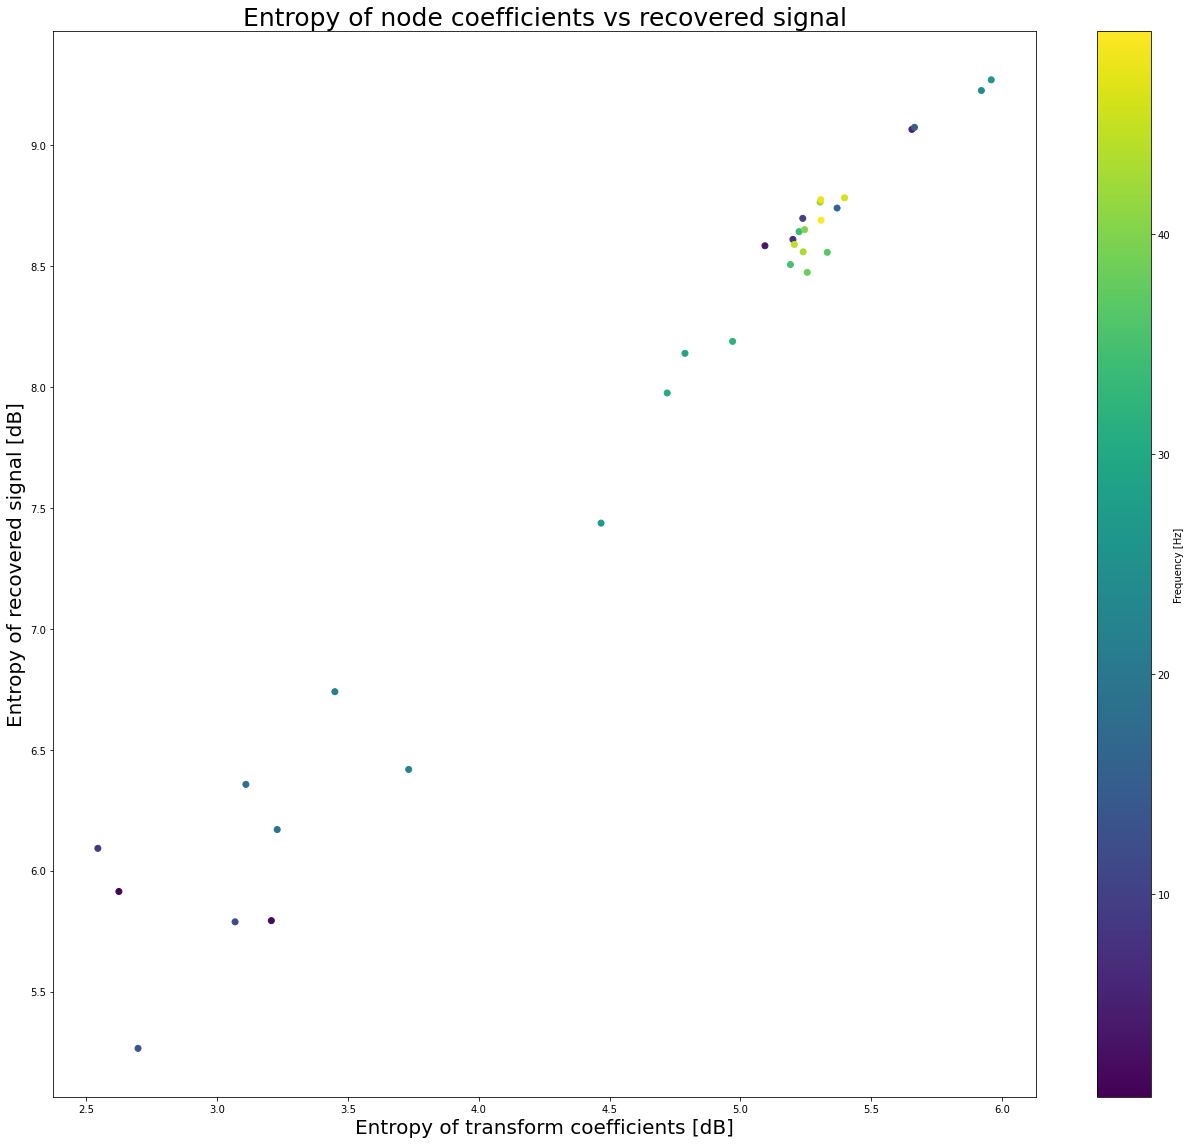

In [43]:
# gather data
coef_entropy = [node.entropy for node, *_ in rec]
entropy = [stats.entropy(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_entropy, entropy, c=cent_freqs)
ax.set_title("Entropy of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Entropy of transform coefficients [dB]", fontsize=20)
ax.set_ylabel("Entropy of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()